# Explainable kidney-CT classification: ground truth → training/testing → XAI

# This project's implementation is mostly based on the pipeline proposed by
Vasu, A., Srivastava, S. S., & Olivia, D. (2025, December). Explainable Deep Learning for Kidney CT Scan Classification. In 2025 International Conference on Modeling, Simulation & Intelligent Computing (MoSICom) (pp. 141-146). IEEE.

**Structure**
- **Part 1** Dataset and ground truth: what the labels contain and what they do *not*.
- **Part 2** Training and testing: VGG16, temperature scaling, ECE, leakage check.
- **Part 3** XAI: Grad-CAM, Score-CAM, LIME and what they add (faithfulness, error analysis, triage, refinement).

In [1]:
# LIME is not preinstalled on Kaggle (needs Internet = On). scikit-image is already available.
!pip install -q lime

## 0. Settings, imports and constants

In [2]:
%matplotlib inline
import os
import re
import json
import argparse
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import minimize_scalar
from scipy.special import softmax, logsumexp
from scipy.stats import rankdata
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
tf.autograph.set_verbosity(0)       # silence harmless autograph notes from tf.data lambdas

# ----------------------------------------------------------------------------
# Global constants
# ----------------------------------------------------------------------------
IMG = 224                                   # [P Sec. III-A / Table III] 224x224x3 input
BATCH = 32                                  # [P Table III] batch size 32
SEED = 42                                   # [P Sec. V-A] fixed random seed
LAST_CONV = "block5_conv3"                  # last conv layer of VGG16 -> CAM target
CLASSES = ["Cyst", "Normal", "Stone", "Tumor"]   # folder names in the Kaggle data
IMG_EXT = (".jpg", ".jpeg", ".png")
TRAPZ = getattr(np, "trapezoid", None) or np.trapz     # numpy 1.x / 2.x compatible

# Class counts reported in [P Sec. III-A] - used to verify we loaded the same data
PAPER_COUNTS = {"Normal": 5077, "Cyst": 3709, "Tumor": 2283, "Stone": 1377}
# Headline numbers reported by the paper - printed next to ours for comparison
PAPER_RESULTS = {"accuracy": 0.942, "macro_f1": 0.925, "ece": 0.020, "T": 1.7,
                 "baseline_acc": 0.895, "baseline_ece": 0.078}

# General radiology orientation cues shown next to the ground-truth examples.
# NOTE: these are textbook cues, NOT annotations shipped with the dataset.
# The dataset only has an image-level label (no lesion masks / boxes).
CUES = {
    "Normal": "IDENTIFY: kidneys of normal size/contour, homogeneous parenchyma, "
              "no focal lesion.   IGNORE: spine, bowel, table, burned-in text.",
    "Cyst":   "IDENTIFY: round, well-circumscribed, thin-walled, fluid-density lesion.   "
              "IGNORE: fat/bowel/vessels that merely sit next to the kidney.",
    "Stone":  "IDENTIFY: very bright (calcific) focus inside the kidney / collecting system.   "
              "IGNORE: bone (spine, ribs) and other bright non-renal structures.",
    "Tumor":  "IDENTIFY: solid, often heterogeneous mass that distorts the kidney contour.   "
              "IGNORE: normal parenchyma, adjacent organs.",
}

In [3]:
# ----------------------------- USER SETTINGS ---------------------------------
import os
from types import SimpleNamespace

KAGGLE_IN = "/kaggle/input"
DS = os.path.join(KAGGLE_IN, "ct-kidney-dataset-normal-cyst-tumor-and-stone")

a = SimpleNamespace(
    data_dir        = DS if os.path.isdir(DS) else KAGGLE_IN,  # the loader searches for the Cyst/Normal/Stone/Tumor folders
    out_dir         = "/kaggle/working/results",
    weights         = "imagenet",   # or a path to a VGG16 notop .h5 file when Internet is off
    epochs          = 10,           # [P Table III]
    split           = "random",     # "random" = paper's image-level split; "grouped" = proxy for patient-level (see Part 2)
    skip_train      = False,        # True: reuse the model saved in out_dir
    run_baseline    = False,        # True: also train the frozen baseline [P Table II] (adds time)
    n_examples      = 5,            # ground-truth examples per class shown in Part 1
    n_eval          = 200,          # test images used for XAI statistics (Part 3); lower = faster
    n_lime          = 20,           # how many of those also get LIME numbers (LIME is slow)
    lime_samples    = 500,
    score_cam_k     = 64,           # channels used by Score-CAM
    roi_csv         = None,         # optional CSV filename,x1,y1,x2,y2 with lesion boxes
    limit_per_class = None,         # debug: e.g. 100 for a quick dry run
)
os.makedirs(a.out_dir, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Dataset root:", a.data_dir)

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Dataset root: /kaggle/input


## Shared helpers (image loading, augmentation, model, predictor)
Defined first because Parts 1–3 all use them.

In [4]:
# ============================================================================
#                        shared image / model helpers
# ============================================================================
def load_tf(path):
    """Decode, resize to 224x224 and scale to [0,1]   [P Sec. III-A]."""
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    return tf.image.resize(img, (IMG, IMG)) / 255.0


def load_np(path):
    return load_tf(path).numpy().astype(np.float32)


# On-the-fly augmentation, training set only   [P Sec. V-A]
AUG = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),   # horizontal + vertical flips
    layers.RandomRotation(0.05),                    # random rotations
    layers.RandomContrast(0.2),                     # contrast adjustment
])


def make_ds(df, train=False):
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, df.label.values.astype("int32")))
    if train:
        ds = ds.shuffle(len(df), seed=SEED)
    ds = ds.map(lambda p, y: (load_tf(p), y), num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        ds = ds.map(lambda x, y: (AUG(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)


def build_model(weights="imagenet", finetune=True, dropout=0.5):
    """
    VGG16 + custom head   [P Sec. III-B]: ImageNet weights, Dense(256), Dropout(0.5),
    Softmax(4); only the deeper conv blocks are fine-tuned, shallow layers frozen.
    finetune=False / dropout=0 gives the paper's 'baseline' row of Table II.
    The last Dense layer is kept LINEAR ('logits') and softmax is a separate layer,
    because temperature scaling [Guo17] divides the logits by T.
    """
    base = keras.applications.VGG16(include_top=False, weights=weights,
                                    input_shape=(IMG, IMG, 3))
    for layer in base.layers:
        # "last two convolutional blocks" unfrozen [P Sec. IV-B]
        layer.trainable = bool(finetune and layer.name.startswith(("block4", "block5")))
    if weights is None:                               # no pretrained weights -> train all
        for layer in base.layers:
            layer.trainable = True
    x = layers.GlobalAveragePooling2D()(base.output)  # pooling choice not stated in paper
    x = layers.Dense(256, activation="relu")(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    logits = layers.Dense(len(CLASSES), name="logits")(x)
    probs = layers.Activation("softmax", name="probs")(logits)
    model = keras.Model(base.input, probs)
    model.compile(optimizer=keras.optimizers.Adam(1e-4),            # [P Table III] lr 1e-4
                  loss="sparse_categorical_crossentropy",           # [P Sec. III-B]
                  metrics=["accuracy"])
    return model


class Predictor:
    """Wraps the model so that every prediction is temperature-scaled [Guo17]."""
    def __init__(self, model, T=1.0):
        self.logit_model = keras.Model(model.input, model.get_layer("logits").output)
        self.T = T

    def logits(self, x):
        return self.logit_model.predict(np.asarray(x, np.float32), batch_size=BATCH, verbose=0)

    def probs(self, x):                       # also usable as LIME's classifier_fn
        return softmax(self.logits(x) / self.T, axis=1)

I0000 00:00:1793541296.422495      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793541296.425749      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## Part 1 – Dataset and ground truth
**Goal:** see exactly what the ground truth is (one class label per 2-D slice), what the model is supposed to identify and what it should ignore, and audit the data for shortcuts (image size / brightness differing between classes).
The dataset has **no lesion masks and no patient IDs**, so the XAI evaluation in Part 3 cannot use pixel-level ground truth unless you supply boxes.

In [5]:
# ============================================================================
#                              PART 1  -  DATASET
# ============================================================================
def get_data_dir(a):
    """Return the dataset root; download from Kaggle with kagglehub if needed."""
    if a.data_dir:
        return a.data_dir
    import kagglehub                         # pip install kagglehub
    return kagglehub.dataset_download(
        "nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone")


def index_dataset(root, limit_per_class=None):
    """
    Walk the folder tree and build a table (path, label_name, label, file_idx).
    The ground truth in this dataset is ONLY the folder name = image-level class.
    """
    rows = []
    for dirpath, _, files in os.walk(root):
        cname = os.path.basename(dirpath)
        if cname in CLASSES:
            for f in sorted(files):
                if f.lower().endswith(IMG_EXT):
                    rows.append((os.path.join(dirpath, f), cname, f))
    df = pd.DataFrame(rows, columns=["path", "label_name", "filename"])
    # Kaggle zips sometimes contain the same folder twice -> drop duplicates
    df = df.drop_duplicates(subset=["label_name", "filename"]).reset_index(drop=True)
    if limit_per_class:                                  # debug option
        df = df.groupby("label_name").head(limit_per_class).reset_index(drop=True)
    df["label"] = df.label_name.map({c: i for i, c in enumerate(CLASSES)})
    # Files are named like "Cyst- (123).jpg"; consecutive numbers are typically
    # neighbouring slices of the same study -> used for the grouped split below.
    num = df.filename.str.extract(r"\((\d+)\)")[0]
    df["file_idx"] = pd.to_numeric(num, errors="coerce").fillna(
        df.groupby("label_name").cumcount()).astype(int)
    return df


def part1_dataset(a, root, out):
    """PART 1: load data, audit it, and show what the ground truth does / does not contain."""
    print("\n" + "=" * 78 + "\nPART 1 - DATASET AND GROUND TRUTH\n" + "=" * 78)
    df = index_dataset(root, a.limit_per_class)

    # --- 1a. class balance vs. the paper [P Sec. III-A] ----------------------
    counts = df.label_name.value_counts()
    print(f"Images found: {len(df)}   (paper: 12,446)")
    for c in CLASSES:
        print(f"  {c:7s} found={counts.get(c, 0):5d}   paper={PAPER_COUNTS[c]:5d}")
    if not a.limit_per_class and len(df) != 12446:
        print("  [!] Total differs from the paper - check for duplicated folders.")

    # --- 1b. shortcut audit [EXTENSION] --------------------------------------
    # A CNN can "cheat" if image size / brightness differs between classes.
    # We read only the image headers (fast) plus a tiny thumbnail.
    sizes, means = [], []
    for p in df.path:
        with Image.open(p) as im:
            sizes.append(f"{im.size[0]}x{im.size[1]}")
            means.append(np.asarray(im.convert("L").resize((16, 16)), float).mean() / 255)
    df["size"], df["mean_intensity"] = sizes, means
    print("\nImage size by class (top 3 sizes per class) - if a size appears in "
          "only one class, the model could use it as a shortcut:")
    for c in CLASSES:
        print(f"  {c:7s}", df[df.label_name == c]["size"].value_counts().head(3).to_dict())
    print("Mean intensity by class:",
          df.groupby("label_name").mean_intensity.mean().round(3).to_dict())

    # --- 1c. figure: class distribution -------------------------------------
    fig, ax = plt.subplots(figsize=(5, 3.2))
    ax.bar(CLASSES, [counts.get(c, 0) for c in CLASSES], color="#4c78a8")
    ax.set_ylabel("images"); ax.set_title("Class distribution (image-level ground truth)")
    plt.tight_layout(); plt.savefig(f"{out}/part1_class_distribution.png", dpi=140); plt.show()

    # --- 1d. figure: ground-truth examples + what to identify / ignore -------
    rng = np.random.default_rng(SEED)
    n = a.n_examples
    fig, axes = plt.subplots(len(CLASSES), n, figsize=(2.6 * n, 3.0 * len(CLASSES)))
    axes = np.atleast_2d(axes)
    for r, c in enumerate(CLASSES):
        sub = df[df.label_name == c]
        pick = sub.sample(min(n, len(sub)), random_state=SEED) if len(sub) else sub
        for k in range(n):
            ax = axes[r, k]; ax.axis("off")
            if k < len(pick):
                ax.imshow(load_np(pick.path.iloc[k]))
                ax.set_title(f"GROUND TRUTH: {c}", fontsize=8)
        axes[r, 0].text(0, -0.12, CUES[c], transform=axes[r, 0].transAxes,
                        fontsize=7, va="top", wrap=True)
    plt.suptitle("Ground truth = one class label per image (no lesion masks). "
                 "Cues below each row are textbook hints, not dataset annotations.",
                 fontsize=9)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(f"{out}/part1_ground_truth_examples.png", dpi=140); plt.show()

    print("\nWHAT THE GROUND TRUTH CONTAINS : one class label per 2-D image.")
    print("WHAT IT DOES NOT CONTAIN       : lesion location/masks, patient IDs, "
          "scan phase labels.")
    print("  -> We therefore cannot measure 'did the heat-map hit the lesion?' "
          "directly.\n     Part 3 uses faithfulness tests + off-body attention "
          "instead, and accepts\n     optional boxes via --roi_csv.")
    df.to_csv(f"{out}/part1_dataset_index.csv", index=False)
    return df


PART 1 - DATASET AND GROUND TRUTH
Images found: 12446   (paper: 12,446)
  Cyst    found= 3709   paper= 3709
  Normal  found= 5077   paper= 5077
  Stone   found= 1377   paper= 1377
  Tumor   found= 2283   paper= 2283

Image size by class (top 3 sizes per class) - if a size appears in only one class, the model could use it as a shortcut:
  Cyst    {'512x512': 2247, '798x646': 240, '705x569': 140}
  Normal  {'512x512': 3274, '840x680': 171, '804x651': 150}
  Stone   {'512x512': 848, '1236x1001': 118, '888x719': 76}
  Tumor   {'512x512': 1340, '768x622': 177, '882x714': 131}
Mean intensity by class: {'Cyst': 0.105, 'Normal': 0.177, 'Stone': 0.14, 'Tumor': 0.144}


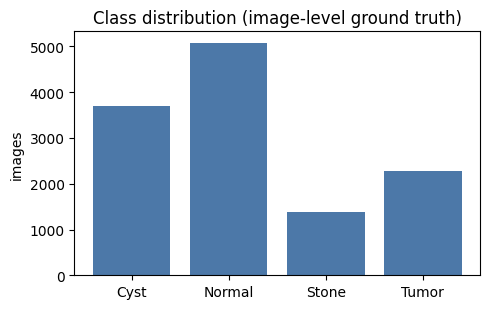

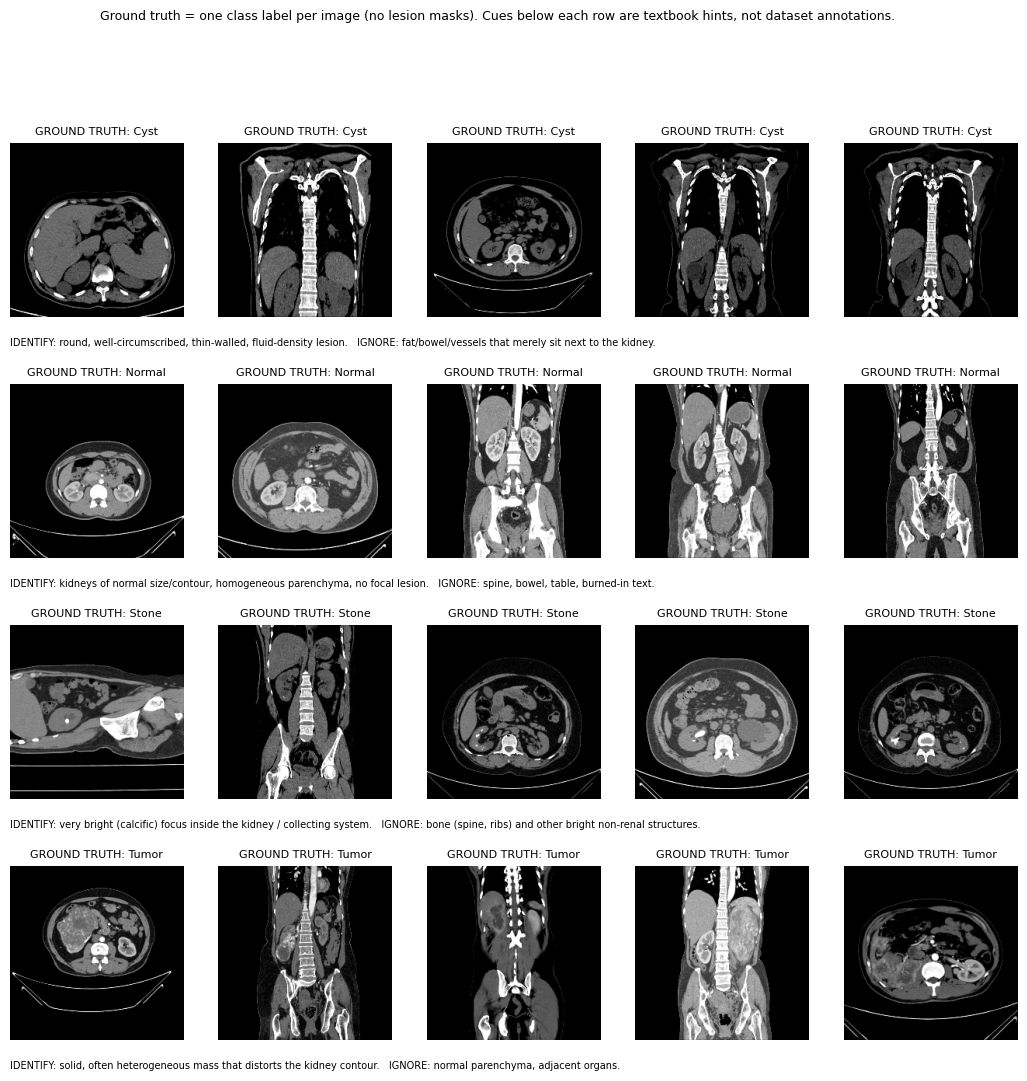


WHAT THE GROUND TRUTH CONTAINS : one class label per 2-D image.
WHAT IT DOES NOT CONTAIN       : lesion location/masks, patient IDs, scan phase labels.
  -> We therefore cannot measure 'did the heat-map hit the lesion?' directly.
     Part 3 uses faithfulness tests + off-body attention instead, and accepts
     optional boxes via --roi_csv.


,path,label_name,filename,label,file_idx,size,mean_intensity
0,/kaggle/input/datasets/nazmul0087/ct-kidney-da...,Cyst,Cyst- (1).jpg,0,1,705x569,0.159773
1,/kaggle/input/datasets/nazmul0087/ct-kidney-da...,Cyst,Cyst- (10).jpg,0,10,512x512,0.085968
2,/kaggle/input/datasets/nazmul0087/ct-kidney-da...,Cyst,Cyst- (100).jpg,0,100,512x512,0.104320
3,/kaggle/input/datasets/nazmul0087/ct-kidney-da...,Cyst,Cyst- (1000).jpg,0,1000,512x512,0.049525
4,/kaggle/input/datasets/nazmul0087/ct-kidney-da...,Cyst,Cyst- (1001).jpg,0,1001,512x512,0.049249


In [6]:
df = part1_dataset(a, get_data_dir(a), a.out_dir)
df.head()

## Part 2 – Training and testing
VGG16 (ImageNet) with the last two conv blocks fine-tuned, Dense(256) → Dropout(0.5) → Softmax(4) [P Sec. III-B, Table III]. Temperature scaling is fitted on the **validation** set, ECE is computed with 10 bins [P Eq. 1–2], and every metric is recomputed from the real predictions (the paper's Fig. 1 confusion matrix is inconsistent with its headline 94.2 %). A near-duplicate check estimates how much slice-level leakage could inflate the score.

In [7]:
# ============================================================================
#                      PART 2  -  TRAINING AND TESTING
# ============================================================================
def split_data(df, mode):
    """
    'random'  : stratified 70/15/15 image-level split   [P Sec. III-A, V-A]
    'grouped' : [EXTENSION] heuristic group split. Neighbouring file numbers are
                probably adjacent slices of one study, so blocks of 50 consecutive
                files of a class are kept together. The dataset has no patient IDs,
                so this is only a PROXY for a patient-level split.
    """
    if mode == "random":
        tr, tmp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
        va, te = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=SEED)
        return tr, va, te
    groups = df.label_name + "_" + (df.file_idx // 50).astype(str)
    sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
    folds = [idx for _, idx in sgkf.split(df, df.label, groups)]
    te, va = df.iloc[folds[0]], df.iloc[folds[1]]
    tr = df.iloc[np.concatenate(folds[2:])]
    return tr, va, te


def fit_temperature(val_logits, val_y):
    """
    Temperature scaling [Guo17; P Sec. IV-E]: find a single T minimising the NLL on
    the VALIDATION set. (Paper reports T=1.7 but not which set it was fitted on;
    fitting on test would leak.) Dividing logits by T never changes the argmax,
    so it can change ECE but NOT accuracy.
    """
    n = len(val_y)

    def nll(T):
        z = val_logits / T
        logp = z - logsumexp(z, axis=1, keepdims=True)
        return -logp[np.arange(n), val_y].mean()

    return float(minimize_scalar(nll, bounds=(0.05, 10.0), method="bounded").x)


def ece_score(probs, y, n_bins=10):
    """Expected Calibration Error, K=10 equal-width bins   [P Eq. (1)/(2), Sec. V-C]."""
    conf, pred = probs.max(1), probs.argmax(1)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())   # |B_i|/n * |acc - conf|
    return ece


def reliability_diagram(probs, y, path, title, n_bins=10):
    """Reliability diagram   [P Fig. 4]. Bins with <5 samples are skipped (too noisy)."""
    conf, pred = probs.max(1), probs.argmax(1)
    correct = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    plt.figure(figsize=(4.5, 4.5))
    plt.plot([0, 1], [0, 1], "--", c="orange", label="Perfectly calibrated")
    plt.plot(xs, ys, "o-", label="Model")
    plt.xlabel("Confidence"); plt.ylabel("Accuracy"); plt.title(title)
    plt.legend(); plt.tight_layout(); plt.savefig(path, dpi=140); plt.show()


def thumbs(paths):
    """32x32 grey, zero-mean, unit-norm vectors for the near-duplicate (leakage) check."""
    v = np.stack([np.asarray(Image.open(p).convert("L").resize((32, 32)), np.float32).ravel()
                  for p in paths])
    v -= v.mean(1, keepdims=True)
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-8)


def part2_train_test(a, df, out):
    """PART 2: split, train, calibrate, evaluate, and check for train/test leakage."""
    print("\n" + "=" * 78 + "\nPART 2 - TRAINING AND TESTING\n" + "=" * 78)
    tr, va, te = split_data(df, a.split)
    print(f"Split mode '{a.split}': train={len(tr)}  val={len(va)}  test={len(te)} "
          f"(paper: 70/15/15 -> test should be ~15% = {int(0.15 * len(df))})")
    ds_tr, ds_va, ds_te = make_ds(tr, True), make_ds(va), make_ds(te)

    model_path = f"{out}/vgg16_kidney.keras"
    if a.skip_train and os.path.exists(model_path):
        model = keras.models.load_model(model_path)
        print("Loaded saved model.")
    else:
        model = build_model(a.weights)
        hist = model.fit(ds_tr, validation_data=ds_va, epochs=a.epochs,   # [P Table III] 10 epochs
                         callbacks=[keras.callbacks.EarlyStopping(          # [P Sec. V-B]
                             monitor="val_loss", patience=5, restore_best_weights=True)])
        model.save(model_path)
        fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))                      # cf. [P Fig. 2]
        ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val")
        ax[0].set_title("Loss"); ax[0].legend()
        ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="val")
        ax[1].set_title("Accuracy"); ax[1].legend()
        plt.tight_layout(); plt.savefig(f"{out}/part2_training_curves.png", dpi=140); plt.show()

    # ---- logits on val and test; temperature fitted on VAL only -------------
    lm = Predictor(model)
    z_va, z_te = lm.logit_model.predict(ds_va, verbose=0), lm.logit_model.predict(ds_te, verbose=0)
    y_va, y_te = va.label.values, te.label.values
    T = fit_temperature(z_va, y_va)
    p_raw, p_cal = softmax(z_te, 1), softmax(z_te / T, 1)
    ece_raw, ece_cal = ece_score(p_raw, y_te), ece_score(p_cal, y_te)
    reliability_diagram(p_raw, y_te, f"{out}/part2_reliability_before.png", "Before temperature scaling")
    reliability_diagram(p_cal, y_te, f"{out}/part2_reliability_after.png", f"After scaling (T={T:.2f})")

    # ---- metrics recomputed from the real predictions   [P Table IV, Fig. 1] -
    pred = p_cal.argmax(1)
    acc = float((pred == y_te).mean())
    rep = classification_report(y_te, pred, target_names=CLASSES, digits=3, output_dict=True, zero_division=0)
    cm = confusion_matrix(y_te, pred, labels=range(len(CLASSES)))
    print(f"\nTemperature T = {T:.3f}   (paper: {PAPER_RESULTS['T']})")
    print(f"ECE before = {ece_raw:.4f}  after = {ece_cal:.4f}   (paper: 0.078 -> 0.020)")
    print(f"Accuracy = {acc:.4f}   macro-F1 = {rep['macro avg']['f1-score']:.4f}   "
          f"(paper: {PAPER_RESULTS['accuracy']} / {PAPER_RESULTS['macro_f1']})")
    print(classification_report(y_te, pred, target_names=CLASSES, digits=3, zero_division=0))
    print("Confusion matrix (rows = ground truth, cols = prediction):\n",
          pd.DataFrame(cm, index=CLASSES, columns=CLASSES))
    print(f"Accuracy recomputed from the confusion-matrix diagonal: {np.trace(cm) / cm.sum():.4f}")
    print("NOTE: scaling by T cannot change the argmax, so accuracy is identical "
          "before/after scaling\n      (the paper's Table II shows +1.6 points at the "
          "temperature-scaling step - not possible).")
    fig, ax = plt.subplots(figsize=(4.8, 4.2))                              # cf. [P Fig. 1]
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(cmn, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(4)); ax.set_yticklabels(CLASSES)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", color="w", fontsize=7)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth"); ax.set_title("Row-normalised confusion matrix")
    plt.tight_layout(); plt.savefig(f"{out}/part2_confusion_matrix.png", dpi=140); plt.show()

    # ---- optional ablation: the paper's frozen baseline   [P Table II row 1] --
    if a.run_baseline:
        base = build_model(a.weights, finetune=False, dropout=0.0)
        base.fit(ds_tr, validation_data=ds_va, epochs=a.epochs, verbose=0)
        zb = Predictor(base).logit_model.predict(ds_te, verbose=0)
        print(f"\nBaseline (frozen VGG16, no dropout): acc={(zb.argmax(1) == y_te).mean():.4f} "
              f"ECE={ece_score(softmax(zb, 1), y_te):.4f}   (paper: 0.895 / 0.078)")

    # ---- [EXTENSION] leakage check -------------------------------------------
    # The paper splits individual images and never says the split is by patient.
    # If test slices have near-identical twins in the training set, accuracy is inflated.
    print("\nLEAKAGE CHECK (nearest-neighbour similarity of each test image to the training set)")
    sim = (thumbs(te.path) @ thumbs(tr.path).T).max(1)
    dup = sim > 0.98
    print(f"  test images with a near-duplicate (cos>0.98) in train: {dup.mean() * 100:.1f}%")
    if dup.any() and (~dup).any():
        print(f"  accuracy on near-duplicates: {(pred[dup] == y_te[dup]).mean():.3f}   "
              f"on the rest: {(pred[~dup] == y_te[~dup]).mean():.3f}")
    print("  -> a high share means the headline accuracy is optimistic; "
          "rerun with --split grouped to compare.")

    te = te.copy()
    te["pred"], te["conf"] = pred, p_cal.max(1)
    te.to_csv(f"{out}/part2_test_predictions.csv", index=False)
    return model, T, te


PART 2 - TRAINING AND TESTING
Split mode 'random': train=8712  val=1867  test=1867 (paper: 70/15/15 -> test should be ~15% = 1866)
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/10


I0000 00:00:1793541497.025226     154 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


273/273 ━━━━━━━━━━━━━━━━━━━━ 174s 537ms/step - accuracy: 0.6359 - loss: 0.8846 - val_accuracy: 0.8623 - val_loss: 0.3630
Epoch 2/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 122s 447ms/step - accuracy: 0.9306 - loss: 0.1985 - val_accuracy: 0.9582 - val_loss: 0.1201
Epoch 3/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 122s 448ms/step - accuracy: 0.9713 - loss: 0.0875 - val_accuracy: 0.9888 - val_loss: 0.0393
Epoch 4/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 122s 448ms/step - accuracy: 0.9801 - loss: 0.0632 - val_accuracy: 0.9839 - val_loss: 0.0470
Epoch 5/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 123s 452ms/step - accuracy: 0.9885 - loss: 0.0355 - val_accuracy: 0.9930 - val_loss: 0.0228
Epoch 6/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 123s 450ms/step - accuracy: 0.9866 - loss: 0.0406 - val_accuracy: 0.9839 - val_loss: 0.0529
Epoch 7/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 123s 450ms/step - accuracy: 0.9939 - loss: 0.0217 - val_accuracy: 0.9968 - val_loss: 0.0088
Epoch 8/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 123s 449ms/step - accuracy: 0.9889 - loss: 0.03

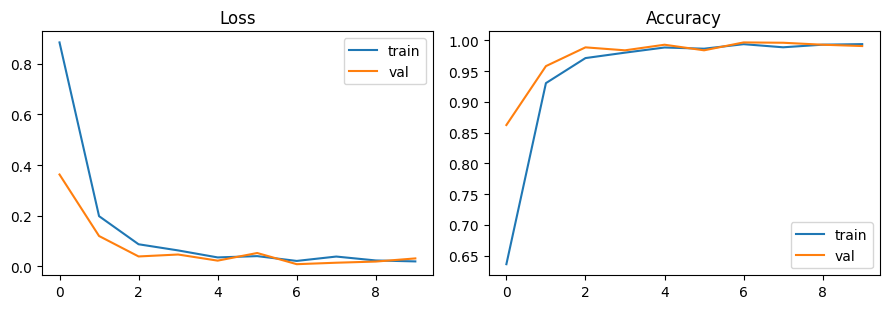

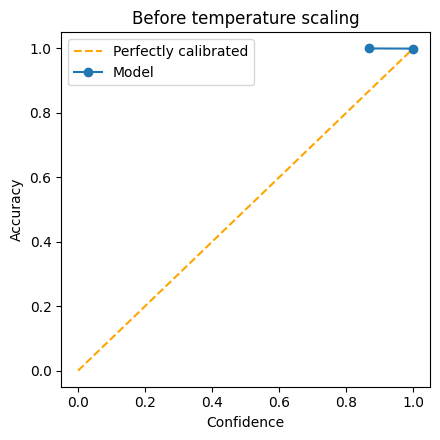

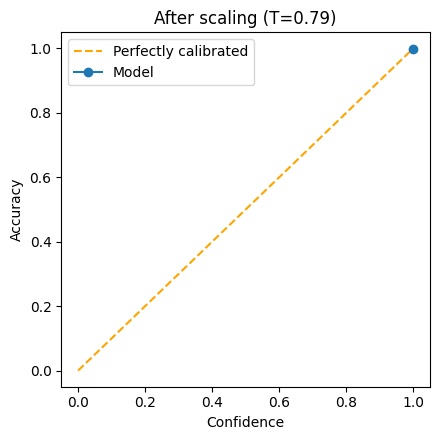


Temperature T = 0.787   (paper: 1.7)
ECE before = 0.0016  after = 0.0011   (paper: 0.078 -> 0.020)
Accuracy = 0.9979   macro-F1 = 0.9976   (paper: 0.942 / 0.925)
              precision    recall  f1-score   support

        Cyst      1.000     0.998     0.999       557
      Normal      0.996     1.000     0.998       761
       Stone      0.995     1.000     0.998       207
       Tumor      1.000     0.991     0.996       342

    accuracy                          0.998      1867
   macro avg      0.998     0.997     0.998      1867
weighted avg      0.998     0.998     0.998      1867

Confusion matrix (rows = ground truth, cols = prediction):
         Cyst  Normal  Stone  Tumor
Cyst     556       0      1      0
Normal     0     761      0      0
Stone      0       0    207      0
Tumor      0       3      0    339
Accuracy recomputed from the confusion-matrix diagonal: 0.9979
NOTE: scaling by T cannot change the argmax, so accuracy is identical before/after scaling
      (the pa

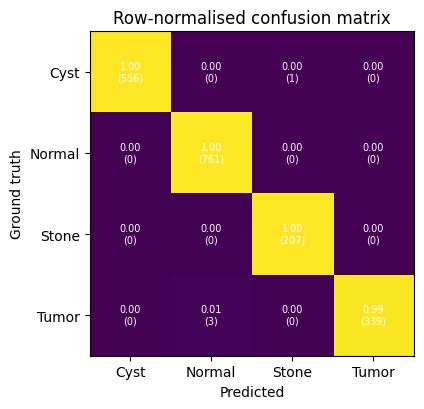


LEAKAGE CHECK (nearest-neighbour similarity of each test image to the training set)
  test images with a near-duplicate (cos>0.98) in train: 99.7%
  accuracy on near-duplicates: 0.998   on the rest: 1.000
  -> a high share means the headline accuracy is optimistic; rerun with --split grouped to compare.


In [8]:
model, T, te = part2_train_test(a, df, a.out_dir)

## Part 3 – Explainability (XAI) against the ground truth
Grad-CAM, Score-CAM and LIME are generated for the **predicted** class, plus a *contrast* map (evidence for the ground-truth class on errors, runner-up class on correct cases).
What the XAI adds is **measured**, not assumed:
- **3a Faithfulness** – deletion/insertion curves vs a random map.
- **3b Localisation / shortcut check** – attention outside the body (and boxes, if provided).
- **3c Triage** – does method agreement / evidence-use tell us which predictions to trust beyond confidence alone?
- **3d Refinement** – re-classify the salient crop and fuse with the original prediction.
- **3e Case studies** – single images with ground truth, prediction, maps and a plain-language reading.

In [9]:
# ============================================================================
#                              PART 3  -  XAI
# ============================================================================
def norm_resize(cam):
    """Upsample a CAM to 224x224 and min-max normalise to [0,1]."""
    cam = tf.image.resize(np.asarray(cam, np.float32)[..., None], (IMG, IMG)).numpy()[..., 0]
    cam = cam - cam.min()
    return cam / (cam.max() + 1e-8)


def grad_cam(grad_model, img, cls):
    """
    Grad-CAM [GradCAM; P Sec. III-C]: weight the last conv feature maps by the
    spatially averaged gradient of the class score, sum, ReLU.
    We use the pre-softmax logit as the class score (as in the original paper).
    """
    x = tf.convert_to_tensor(img[None], tf.float32)
    with tf.GradientTape() as tape:
        conv, logits = grad_model(x, training=False)
        score = logits[:, cls]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0].numpy()
    return norm_resize(cam)


def score_cam(act_model, pred, img, cls, top_k):
    """
    Score-CAM [ScoreCAM; P Sec. III-C]: gradient-free. Each activation map is used as a
    mask on the input; the increase in the class probability becomes that map's weight.
    For speed only the top_k highest-variance channels are used (approximation).
    """
    acts = act_model(img[None], training=False)[0].numpy()               # (14,14,512)
    idx = np.argsort(acts.reshape(-1, acts.shape[-1]).var(0))[-top_k:]
    masks = np.stack([norm_resize(acts[..., i]) for i in idx])           # (k,224,224)
    scores = pred.probs(img[None] * masks[..., None])[:, cls]
    base = pred.probs(np.zeros_like(img)[None])[0, cls]                  # score of a blank image
    w = softmax(scores - base)
    return norm_resize(np.maximum((w[:, None, None] * masks).sum(0), 0))


def lime_map(pred, img, cls, n_samples):
    """
    LIME [LIME; P Sec. III-C]: perturb super-pixels, fit a local linear surrogate.
    Returns a [0,1] heat-map (positive weights only) and the segmentation.
    """
    try:
        from lime import lime_image
    except ImportError:
        return None, None
    ex = lime_image.LimeImageExplainer(random_state=SEED)
    e = ex.explain_instance(img.astype("double"), pred.probs, labels=(cls,), hide_color=0,
                            num_samples=n_samples, batch_size=BATCH, random_seed=SEED)
    heat = np.zeros(img.shape[:2], np.float32)
    for seg, w in e.local_exp[cls]:
        heat[e.segments == seg] = max(w, 0)
    return heat / (heat.max() + 1e-8), e.segments


def top_mask(sal, frac=0.2):
    """Binary mask of the most salient `frac` of the pixels."""
    return sal >= np.quantile(sal, 1 - frac)


def iou_top(s1, s2, frac=0.2):
    """[EXTENSION] agreement between two explanation methods = IoU of their top-20% regions."""
    m1, m2 = top_mask(s1, frac), top_mask(s2, frac)
    return float((m1 & m2).sum() / max((m1 | m2).sum(), 1))


def del_ins(pred, img, cls, sal, steps=20):
    """
    [EXTENSION] Faithfulness tests (Petsiuk et al., RISE, 2018).
      DELETION : progressively blur the most salient pixels; a faithful map makes the
                 class probability collapse quickly  -> LOW area under the curve is good.
      INSERTION: start from a blurred image and reveal the most salient pixels first;
                 a faithful map restores the probability quickly -> HIGH AUC is good.
    A random map is the reference: a map that does not beat random explains nothing.
    Returns (deletion_auc, insertion_auc, drop_when_top20%_removed).
    """
    blur = ndi.gaussian_filter(img, sigma=(12, 12, 0))
    order = np.argsort(sal.ravel())[::-1]
    fi, fb = img.reshape(-1, 3), blur.reshape(-1, 3)
    dels, inss = [], []
    for f in np.linspace(0, 1, steps + 1):
        idx = order[: int(f * order.size)]
        d = fi.copy(); d[idx] = fb[idx]; dels.append(d.reshape(img.shape))
        i = fb.copy(); i[idx] = fi[idx]; inss.append(i.reshape(img.shape))
    p = pred.probs(np.stack(dels + inss))[:, cls]
    pdel, pins = p[: steps + 1], p[steps + 1:]
    x = np.linspace(0, 1, steps + 1)
    return float(TRAPZ(pdel, x)), float(TRAPZ(pins, x)), float(pdel[0] - pdel[steps // 5])


def body_mask(img):
    """
    [EXTENSION] crude body mask (threshold + fill + largest component). Attention
    OUTSIDE it (table, background, burned-in text) is a red flag for shortcut learning.
    """
    g = ndi.gaussian_filter(img.mean(-1), 2) > 0.12
    g = ndi.binary_fill_holes(ndi.binary_closing(g, iterations=3))
    lab, n = ndi.label(g)
    if n == 0:
        return np.ones(g.shape, bool)
    return lab == (1 + int(np.argmax(ndi.sum(g, lab, range(1, n + 1)))))


def crop_to_saliency(img, sal, q=0.7, margin=0.10):
    """Crop to the bounding box of the top-30% saliency, add a margin, resize back to 224."""
    ys, xs = np.where(sal >= np.quantile(sal, q))
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    my, mx = int((y1 - y0) * margin), int((x1 - x0) * margin)
    y0, y1, x0, x1 = max(0, y0 - my), min(IMG, y1 + my), max(0, x0 - mx), min(IMG, x1 + mx)
    if (y1 - y0) < 64 or (x1 - x0) < 64:                    # avoid absurdly tiny crops
        cy, cx = (y0 + y1) // 2, (x0 + x1) // 2
        y0, y1, x0, x1 = max(0, cy - 32), min(IMG, cy + 32), max(0, cx - 32), min(IMG, cx + 32)
    return tf.image.resize(img[y0:y1, x0:x1], (IMG, IMG)).numpy()


def risk_coverage(score, correct, coverages=(1.0, 0.9, 0.8, 0.7, 0.5)):
    """Accuracy when only the `coverage` fraction with the highest score is kept (selective prediction)."""
    order = np.argsort(-score)
    c = correct[order]
    return {cv: float(c[: max(1, int(round(cv * len(c))))].mean()) for cv in coverages}


def overlay(ax, img, cam, title):
    ax.imshow(img); ax.imshow(cam, cmap="jet", alpha=0.45); ax.set_title(title, fontsize=7); ax.axis("off")


def part3_xai(a, model, T, te, out):
    """PART 3: what do Grad-CAM / Score-CAM / LIME add, measured against ground truth?"""
    print("\n" + "=" * 78 + "\nPART 3 - EXPLAINABILITY (XAI)\n" + "=" * 78)
    pred = Predictor(model, T)                              # every probability is calibrated
    grad_model = keras.Model(model.input, [model.get_layer(LAST_CONV).output,
                                           model.get_layer("logits").output])
    act_model = keras.Model(model.input, model.get_layer(LAST_CONV).output)
    rng = np.random.default_rng(SEED)

    # optional ground-truth boxes: CSV with filename,x1,y1,x2,y2 (original-image pixels)
    rois = {}
    if a.roi_csv:
        r = pd.read_csv(a.roi_csv)
        rois = {os.path.basename(f): (x1, y1, x2, y2) for f, x1, y1, x2, y2 in
                zip(r.filename, r.x1, r.y1, r.x2, r.y2)}

    # class-balanced evaluation subset (XAI is expensive)
    per = max(1, a.n_eval // len(CLASSES))
    ev = pd.concat([g.sample(min(len(g), per), random_state=SEED) for _, g in te.groupby("label")]) \
        .reset_index(drop=True)
    print(f"Evaluating explanations on {len(ev)} test images "
          f"({per} per class; small -> treat numbers as indicative, not conclusive).")

    rec, cams, imgs = [], [], []
    for k, row in enumerate(ev.itertuples()):
        img = load_np(row.path)
        z = pred.logits(img[None])[0]
        p = softmax(z / T); c = int(p.argmax())              # model prediction + calibrated confidence
        gc = grad_cam(grad_model, img, c)
        sc = score_cam(act_model, pred, img, c, a.score_cam_k)
        d_gc, i_gc, drop = del_ins(pred, img, c, gc)
        d_sc, i_sc, _ = del_ins(pred, img, c, sc)
        d_rn, i_rn, _ = del_ins(pred, img, c, rng.random((IMG, IMG)))    # random reference
        d_lm = i_lm = np.nan
        if k < a.n_lime:                                      # LIME is slow -> small subset
            lm, _ = lime_map(pred, img, c, a.lime_samples)
            if lm is not None:
                d_lm, i_lm, _ = del_ins(pred, img, c, lm)
        body = body_mask(img)
        off = float((gc * ~body).sum() / (gc.sum() + 1e-8))   # share of Grad-CAM mass off the body
        # --- XAI-assisted refinement: re-predict on the salient crop and fuse the logits
        z_crop = pred.logits(crop_to_saliency(img, gc)[None])[0]
        refined = int(((z + z_crop) / 2).argmax())
        r = dict(path=row.path, truth=row.label, pred=c, conf=float(p.max()), correct=(c == row.label),
                 refined=refined, refined_correct=(refined == row.label),
                 agree=iou_top(gc, sc), del_drop=drop,
                 del_gc=d_gc, ins_gc=i_gc, del_sc=d_sc, ins_sc=i_sc, del_rand=d_rn, ins_rand=i_rn,
                 del_lime=d_lm, ins_lime=i_lm, off_body=off)
        box = rois.get(os.path.basename(row.path))
        if box is not None:                                   # [EXTENSION] true localisation metrics
            with Image.open(row.path) as im:
                w0, h0 = im.size
            x1, y1, x2, y2 = (int(box[0] * IMG / w0), int(box[1] * IMG / h0),
                              int(box[2] * IMG / w0), int(box[3] * IMG / h0))
            inside = np.zeros((IMG, IMG), bool); inside[y1:y2, x1:x2] = True
            yy, xx = np.unravel_index(gc.argmax(), gc.shape)
            r.update(roi_mass=float(gc[inside].sum() / (gc.sum() + 1e-8)), roi_hit=bool(inside[yy, xx]))
        rec.append(r); cams.append(gc); imgs.append(img)
        if (k + 1) % 20 == 0:
            print(f"  explained {k + 1}/{len(ev)}")
    R = pd.DataFrame(rec)
    R.to_csv(f"{out}/part3_xai_metrics.csv", index=False)

    # ---------------------------------------------------------------------
    # 3a. Do the explanations reflect what the model uses?  (faithfulness)
    # ---------------------------------------------------------------------
    print("\n--- 3a. FAITHFULNESS: do the heat-maps point at pixels the model really uses? ---")
    print("Deletion AUC  (lower = better) | Insertion AUC (higher = better)")
    for name, d, i in [("Grad-CAM", "del_gc", "ins_gc"), ("Score-CAM", "del_sc", "ins_sc"),
                       ("LIME", "del_lime", "ins_lime"), ("Random map", "del_rand", "ins_rand")]:
        print(f"  {name:11s} deletion={R[d].mean():.3f}   insertion={R[i].mean():.3f}   (n={R[d].notna().sum()})")
    print(f"  Grad-CAM beats random on {(R.del_gc < R.del_rand).mean() * 100:.0f}% of images (deletion), "
          f"Score-CAM on {(R.del_sc < R.del_rand).mean() * 100:.0f}%.")
    print("  READING: if a method does not beat the random map it is decoration, not explanation.")
    fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
    names, dcols, icols = ["Grad-CAM", "Score-CAM", "LIME", "Random"], \
        ["del_gc", "del_sc", "del_lime", "del_rand"], ["ins_gc", "ins_sc", "ins_lime", "ins_rand"]
    ax[0].bar(names, [R[c].mean() for c in dcols], color="#e45756"); ax[0].set_title("Deletion AUC (lower better)")
    ax[1].bar(names, [R[c].mean() for c in icols], color="#54a24b"); ax[1].set_title("Insertion AUC (higher better)")
    plt.tight_layout(); plt.savefig(f"{out}/part3_faithfulness.png", dpi=140); plt.show()

    # ---------------------------------------------------------------------
    # 3b. Where does the model look relative to the ground truth?
    # ---------------------------------------------------------------------
    print("\n--- 3b. LOCALISATION / SHORTCUT CHECK ---")
    print(f"  Share of Grad-CAM mass OUTSIDE the body: correct={R[R.correct].off_body.mean():.3f}  "
          f"wrong={R[~R.correct].off_body.mean() if (~R.correct).any() else float('nan'):.3f}")
    print("  READING: high off-body attention = model may be using table/background/text "
          "(shortcut) instead of anatomy.")
    if "roi_hit" in R:
        m = R.roi_hit.notna()
        print(f"  Ground-truth boxes: pointing-game hit rate={R[m].roi_hit.mean():.3f}, "
              f"saliency mass inside box={R[m].roi_mass.mean():.3f}")
    else:
        print("  (No lesion boxes available -> pass --roi_csv filename,x1,y1,x2,y2 for true localisation scores.)")
    # mean Grad-CAM per ground-truth class (correctly classified): what does the model use as evidence?
    fig, axes = plt.subplots(1, 4, figsize=(11, 3))
    for j, cname in enumerate(CLASSES):
        sel = [i for i in range(len(R)) if R.truth[i] == j and R.correct[i]]
        axes[j].axis("off")
        if sel:
            overlay(axes[j], np.mean([imgs[i] for i in sel], 0), np.mean([cams[i] for i in sel], 0),
                    f"{cname}: mean Grad-CAM (n={len(sel)})")
    plt.tight_layout(); plt.savefig(f"{out}/part3_class_mean_saliency.png", dpi=140); plt.show()

    # ---------------------------------------------------------------------
    # 3c. How XAI refines predictions - (i) triage: which predictions to trust?
    # ---------------------------------------------------------------------
    print("\n--- 3c. XAI AS A QUALITY SIGNAL: does explanation behaviour tell us which predictions to trust? ---")
    corr = R.correct.values
    score_sets = {"calibrated confidence only": R.conf.values,
                  "method agreement (Grad-CAM vs Score-CAM)": R.agree.values,
                  "deletion drop (evidence is really used)": R.del_drop.values,
                  "COMBINED (mean rank of the three)":
                      (rankdata(R.conf) + rankdata(R.agree) + rankdata(R.del_drop)) / 3}
    print(f"  overall accuracy on this subset: {corr.mean():.3f}")
    print("  accuracy when keeping only the top-X% most trusted predictions (selective prediction):")
    print(f"  {'signal':44s}" + "".join(f"{int(c * 100):>7d}%" for c in (1.0, 0.9, 0.8, 0.7, 0.5)))
    fig = plt.figure(figsize=(5, 3.4))
    for nm, sc_ in score_sets.items():
        rc = risk_coverage(sc_, corr)
        print(f"  {nm:44s}" + "".join(f"{v:8.3f}" for v in rc.values()))
        plt.plot([int(c * 100) for c in rc], list(rc.values()), "o-", label=nm.split(" (")[0], ms=3)
    plt.xlabel("coverage (%)"); plt.ylabel("accuracy"); plt.legend(fontsize=6); plt.gca().invert_xaxis()
    plt.tight_layout(); plt.savefig(f"{out}/part3_risk_coverage.png", dpi=140); plt.show()
    print("  READING: if COMBINED rises faster than 'confidence only', explanation behaviour carries "
          "extra information about errors.\n  If not, XAI here is for human insight, not for automatic filtering.")

    # ---------------------------------------------------------------------
    # 3d. How XAI refines predictions - (ii) re-predict on the salient region
    # ---------------------------------------------------------------------
    print("\n--- 3d. XAI-GUIDED REFINEMENT: re-classify the Grad-CAM crop and fuse with the original prediction ---")
    r2w = int((R.correct & ~R.refined_correct).sum()); w2r = int((~R.correct & R.refined_correct).sum())
    print(f"  accuracy original={R.correct.mean():.3f}  refined={R.refined_correct.mean():.3f}   "
          f"wrong->right: {w2r}   right->wrong: {r2w}")
    print("  READING: an honest experiment - it may help or hurt; with small n differences of a few images are noise.")

    # ---------------------------------------------------------------------
    # 3e. Case studies against the ground-truth label (the "why" for single images)
    # ---------------------------------------------------------------------
    print("\n--- 3e. CASE STUDIES (see part3_case_studies.png) ---")
    med_agree, med_drop = R.agree.median(), R.del_drop.median()
    cases = []
    cases += list(R[R.correct].sort_values("conf", ascending=False).index[:2])        # confident & right
    cases += list(R[~R.correct].sort_values("conf", ascending=False).index[:3])       # confident errors
    cases += list(R[R.correct].sort_values("agree").index[:1])                        # right but maps disagree
    cases = list(dict.fromkeys(cases))
    if cases:
        fig, axes = plt.subplots(len(cases), 5, figsize=(14, 2.9 * len(cases)))
        axes = np.atleast_2d(axes)
        for ri, i in enumerate(cases):
            r, img = R.loc[i], imgs[i]
            c, g = int(r.pred), int(r.truth)
            order = np.argsort(-pred.probs(img[None])[0])
            contrast = g if c != g else int(order[1])       # wrong: evidence for the TRUTH; right: runner-up class
            gc, sc = cams[i], score_cam(act_model, pred, img, c, a.score_cam_k)
            lm, seg = lime_map(pred, img, c, a.lime_samples)
            gc_con = grad_cam(grad_model, img, contrast)
            axes[ri, 0].imshow(img); axes[ri, 0].axis("off")
            axes[ri, 0].set_title(f"GROUND TRUTH: {CLASSES[g]}\nPREDICTED: {CLASSES[c]} ({r.conf:.2f})",
                                  fontsize=7, color="green" if r.correct else "red")
            overlay(axes[ri, 1], img, gc, f"Grad-CAM for '{CLASSES[c]}'")
            overlay(axes[ri, 2], img, sc, f"Score-CAM for '{CLASSES[c]}'")
            if lm is not None:
                overlay(axes[ri, 3], img, lm, f"LIME for '{CLASSES[c]}'")
            else:
                axes[ri, 3].axis("off")
            overlay(axes[ri, 4], img, gc_con,
                    f"Grad-CAM contrast: evidence for '{CLASSES[contrast]}'"
                    + (" (GROUND TRUTH)" if c != g else " (runner-up)"))
            # plain-language reading of the numbers (thresholds = medians of this subset)
            if r.correct and r.agree >= med_agree and r.del_drop >= max(med_drop, 0.05):
                txt = "RIGHT, evidence localised: maps agree and removing the region lowers confidence."
            elif r.correct:
                txt = "RIGHT, but weak/diverging evidence: possible right-for-the-wrong-reason; review."
            elif r.conf >= 0.8:
                txt = "CONFIDENT ERROR: compare last panel - it shows where the evidence for the true class lies."
            else:
                txt = "ERROR with moderate confidence: flag for human review."
            print(f"  [{ri + 1}] GT={CLASSES[g]} pred={CLASSES[c]} conf={r.conf:.2f} agree={r.agree:.2f} "
                  f"drop={r.del_drop:.2f} off-body={r.off_body:.2f}\n      -> {txt}")
            axes[ri, 0].text(0, -0.05, f"agree={r.agree:.2f} drop={r.del_drop:.2f}\n{txt}", transform=axes[ri, 0].transAxes,
                             fontsize=5.5, va="top", wrap=True)
        plt.tight_layout(); plt.savefig(f"{out}/part3_case_studies.png", dpi=140); plt.show()

    # ---------------------------------------------------------------------
    # Summary
    # ---------------------------------------------------------------------
    print("\n" + "=" * 78 + "\nHOW XAI HELPED - SUMMARY (numbers from this run)\n" + "=" * 78)
    print(f"1. VERIFY: Grad-CAM beat a random map on {(R.del_gc < R.del_rand).mean() * 100:.0f}% of images; "
          "explanations that fail this test should not be shown to learners/clinicians.")
    print(f"2. SHORTCUTS: mean off-body attention {R.off_body.mean():.2f} "
          "(close to 0 is reassuring; high values suggest background cues).")
    print("3. ERRORS: the contrast panel in the case studies shows evidence for the ground-truth class "
          "next to evidence for the wrong prediction - this is where explanations are most useful.")
    print(f"4. TRIAGE: see the risk-coverage table - combined XAI signal vs confidence alone.")
    print(f"5. REFINEMENT: crop-and-fuse changed accuracy {R.correct.mean():.3f} -> {R.refined_correct.mean():.3f}.")
    print("CAVEATS: image-level labels only; small evaluation subset; post-hoc maps show correlation "
          "with the model's output, not clinical causation.")


PART 3 - EXPLAINABILITY (XAI)
Evaluating explanations on 200 test images (50 per class; small -> treat numbers as indicative, not conclusive).


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

... (12 outputs left out)

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  explained 20/200
  explained 40/200
  explained 60/200
  explained 80/200
  explained 100/200
  explained 120/200
  explained 140/200
  explained 160/200
  explained 180/200
  explained 200/200

--- 3a. FAITHFULNESS: do the heat-maps point at pixels the model really uses? ---
Deletion AUC  (lower = better) | Insertion AUC (higher = better)
  Grad-CAM    deletion=0.344   insertion=0.958   (n=200)
  Score-CAM   deletion=0.361   insertion=0.957   (n=200)
  LIME        deletion=0.647   insertion=0.965   (n=20)
  Random map  deletion=0.477   insertion=0.477   (n=200)
  Grad-CAM beats random on 66% of images (deletion), Score-CAM on 67%.
  READING: if a method does not beat the random map it is decoration, not explanation.


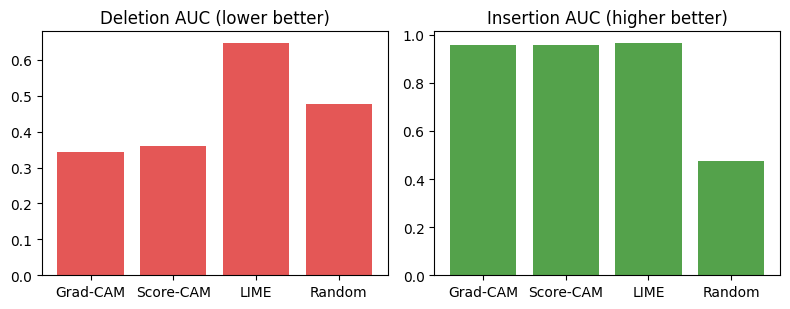


--- 3b. LOCALISATION / SHORTCUT CHECK ---
  Share of Grad-CAM mass OUTSIDE the body: correct=0.251  wrong=0.228
  READING: high off-body attention = model may be using table/background/text (shortcut) instead of anatomy.
  (No lesion boxes available -> pass --roi_csv filename,x1,y1,x2,y2 for true localisation scores.)


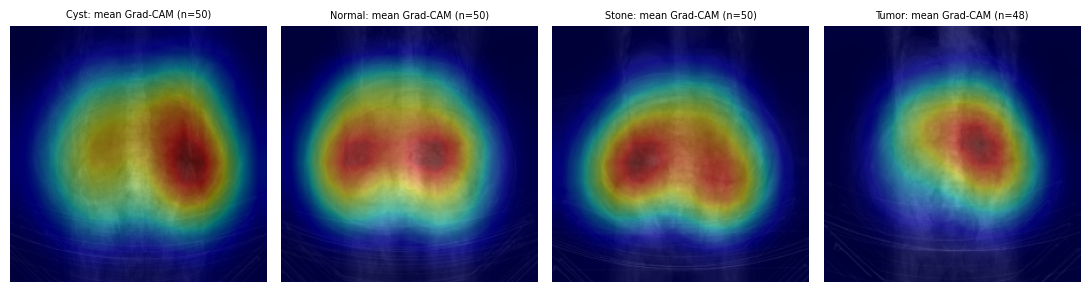


--- 3c. XAI AS A QUALITY SIGNAL: does explanation behaviour tell us which predictions to trust? ---
  overall accuracy on this subset: 0.990
  accuracy when keeping only the top-X% most trusted predictions (selective prediction):
  signal                                          100%     90%     80%     70%     50%
  calibrated confidence only                     0.990   1.000   1.000   1.000   1.000
  method agreement (Grad-CAM vs Score-CAM)       0.990   0.994   1.000   1.000   1.000
  deletion drop (evidence is really used)        0.990   0.989   0.988   0.986   0.990
  COMBINED (mean rank of the three)              0.990   1.000   1.000   1.000   1.000


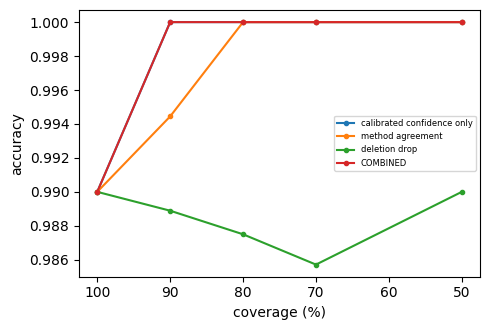

  READING: if COMBINED rises faster than 'confidence only', explanation behaviour carries extra information about errors.
  If not, XAI here is for human insight, not for automatic filtering.

--- 3d. XAI-GUIDED REFINEMENT: re-classify the Grad-CAM crop and fuse with the original prediction ---
  accuracy original=0.990  refined=0.990   wrong->right: 0   right->wrong: 0
  READING: an honest experiment - it may help or hurt; with small n differences of a few images are noise.

--- 3e. CASE STUDIES (see part3_case_studies.png) ---


  0%|          | 0/500 [00:00<?, ?it/s]

  [1] GT=Cyst pred=Cyst conf=1.00 agree=0.94 drop=0.00 off-body=0.29
      -> RIGHT, but weak/diverging evidence: possible right-for-the-wrong-reason; review.


  0%|          | 0/500 [00:00<?, ?it/s]

  [2] GT=Cyst pred=Cyst conf=1.00 agree=0.86 drop=0.43 off-body=0.12
      -> RIGHT, but weak/diverging evidence: possible right-for-the-wrong-reason; review.


  0%|          | 0/500 [00:00<?, ?it/s]

  [3] GT=Tumor pred=Normal conf=0.95 agree=0.76 drop=0.95 off-body=0.18
      -> CONFIDENT ERROR: compare last panel - it shows where the evidence for the true class lies.


  0%|          | 0/500 [00:00<?, ?it/s]

  [4] GT=Tumor pred=Normal conf=0.68 agree=0.77 drop=0.61 off-body=0.28
      -> ERROR with moderate confidence: flag for human review.


  0%|          | 0/500 [00:00<?, ?it/s]

  [5] GT=Tumor pred=Tumor conf=0.98 agree=0.63 drop=0.95 off-body=0.55
      -> RIGHT, but weak/diverging evidence: possible right-for-the-wrong-reason; review.


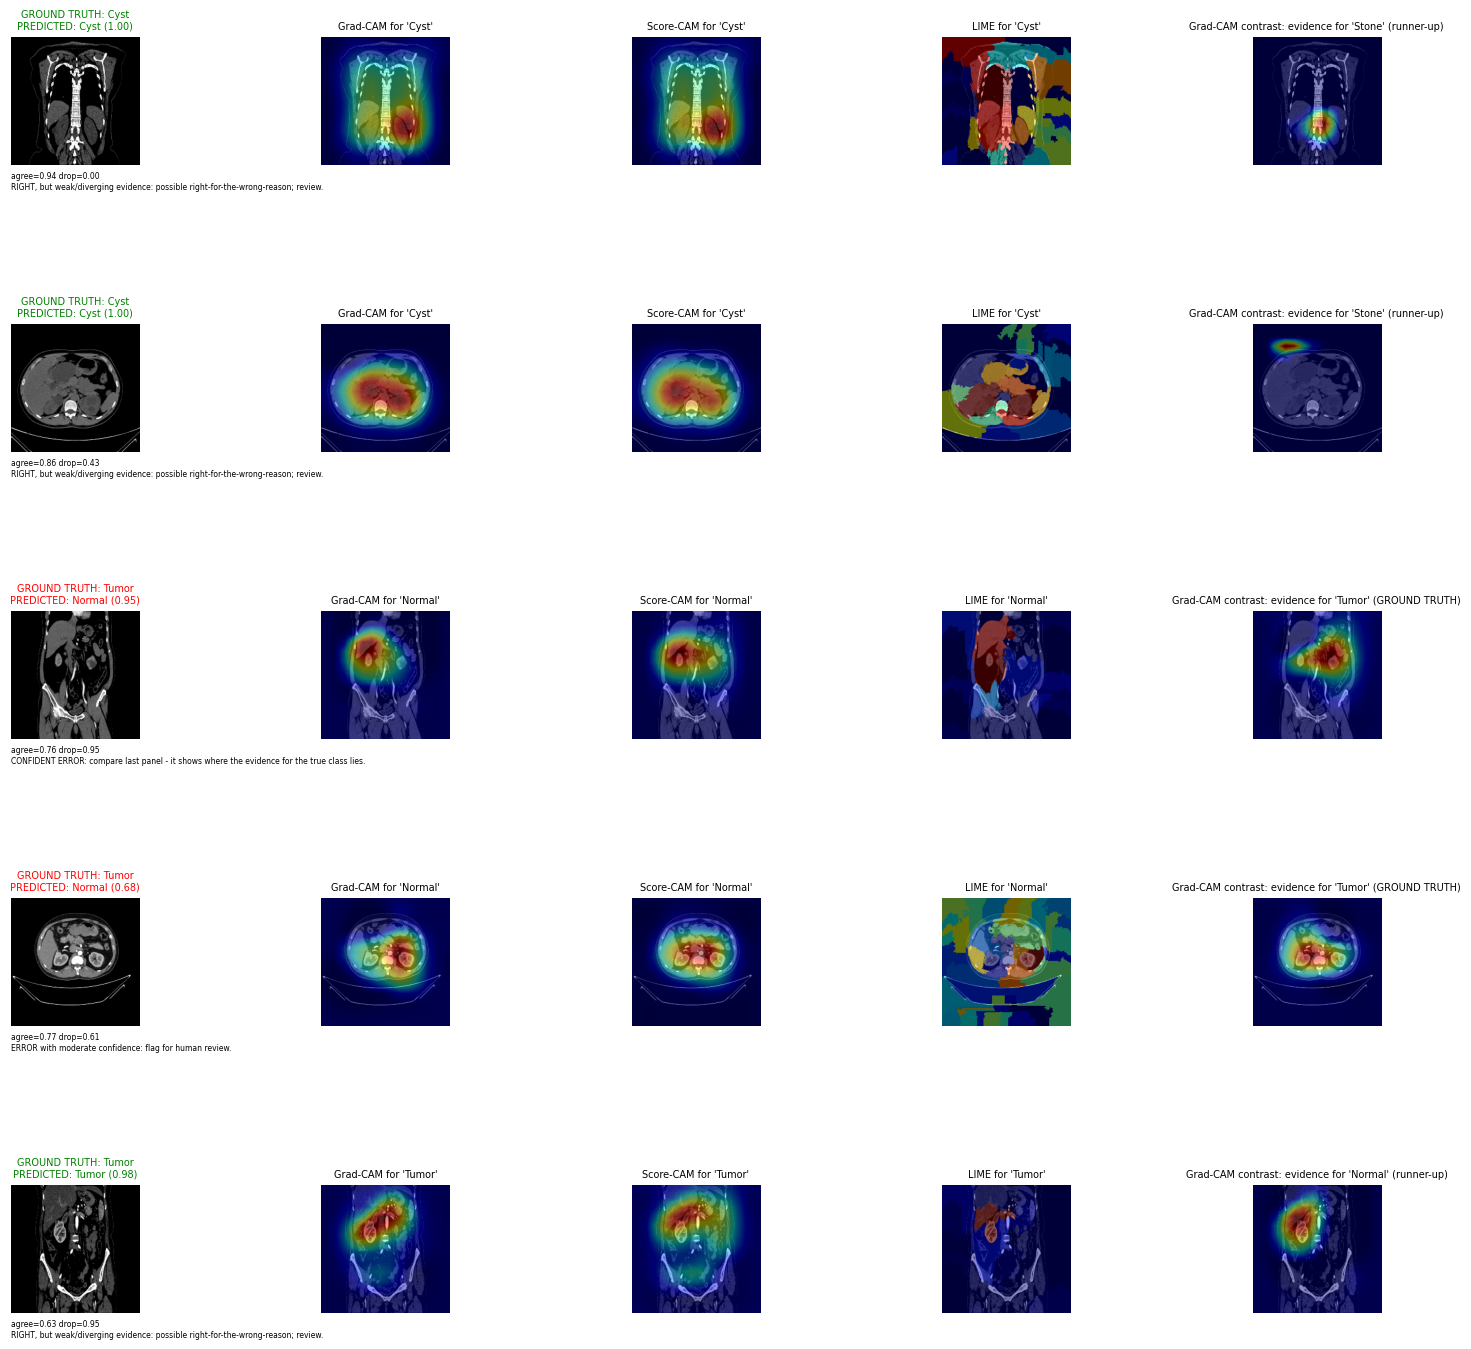


HOW XAI HELPED - SUMMARY (numbers from this run)
1. VERIFY: Grad-CAM beat a random map on 66% of images; explanations that fail this test should not be shown to learners/clinicians.
2. SHORTCUTS: mean off-body attention 0.25 (close to 0 is reassuring; high values suggest background cues).
3. ERRORS: the contrast panel in the case studies shows evidence for the ground-truth class next to evidence for the wrong prediction - this is where explanations are most useful.
4. TRIAGE: see the risk-coverage table - combined XAI signal vs confidence alone.
5. REFINEMENT: crop-and-fuse changed accuracy 0.990 -> 0.990.
CAVEATS: image-level labels only; small evaluation subset; post-hoc maps show correlation with the model's output, not clinical causation.


In [10]:
part3_xai(a, model, T, te, a.out_dir)

## Outputs
All figures, CSVs (`part2_test_predictions.csv`, `part3_xai_metrics.csv`) and the trained model are in `/kaggle/working/results`. They are kept when you *Save Version*.

**How to read the results honestly**
- Image-level split on this dataset can leak neighbouring slices; compare `split="random"` with `split="grouped"`.
- Part 3 statistics use a small class-balanced subset; differences of a few images are noise.
- Post-hoc heat-maps show what correlates with the model's output, not clinical causation.

In [11]:
import glob
for f in sorted(glob.glob(a.out_dir + '/*')): print(os.path.basename(f), f'{os.path.getsize(f)/1e6:.2f} MB')

part1_class_distribution.png 0.02 MB
part1_dataset_index.csv 3.06 MB
part1_ground_truth_examples.png 1.03 MB
part2_confusion_matrix.png 0.04 MB
part2_reliability_after.png 0.03 MB
part2_reliability_before.png 0.04 MB
part2_test_predictions.csv 0.48 MB
part2_training_curves.png 0.05 MB
part3_case_studies.png 0.96 MB
part3_class_mean_saliency.png 0.49 MB
part3_faithfulness.png 0.03 MB
part3_risk_coverage.png 0.05 MB
part3_xai_metrics.csv 0.08 MB
vgg16_kidney.keras 164.38 MB
